# 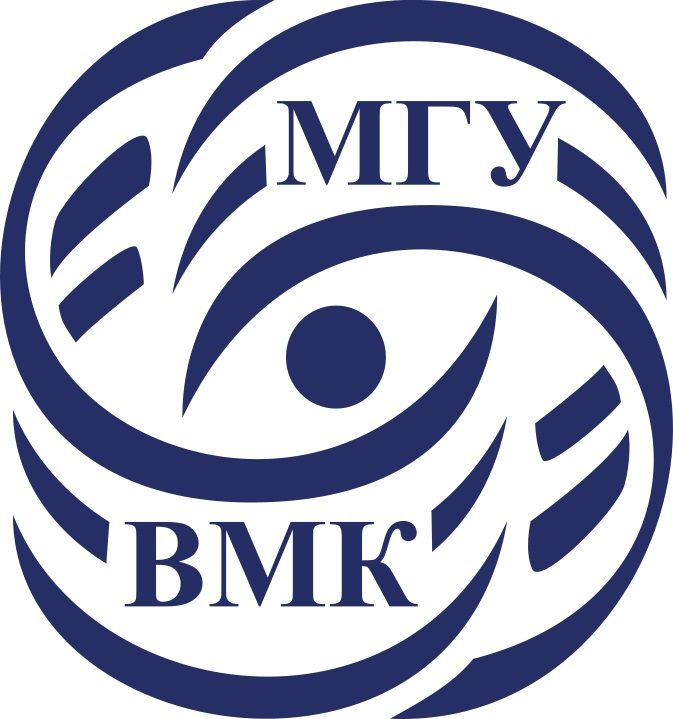

# Машинное обучение. ВМК МГУ

# Практическое задание 4. Knn: классификация и регрессия

## Уровень: <font color='MediumSeaGreen'>**Исследовательский (Research)**</font>

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

-----------
<font color="white" style="opacity:0.2024"></font>







<font color=DarkOrange>**Примерное время выполнения (execution time/время выполнения, если нажать run all) всех ячеек ноутбука при правильной реализации: 10 минут </font>**

# Подготовка рабочей среды

Сначала установим нужные нам версии библиотек. Мы гарантируем, что в данных версиях задание будет корректно отрабатывать.

После установки нужных версий, **возможно,** нужно перезагрузить среду (runtime), но скорее всего вам это не понадобится


На скачивание файла и установку понадобится не более 5 минут.

<font color='OrangeRed'>**Важно!**</font>

Устанавливать нужные версии нужно каждый раз, когда создается новый рантайм. Например, если вы 2 часа подряд делаете это задание, то подготовить библиотеки достаточно 1 раз. Но если вы, например, начали в понедельник, затем закрыли/выключили ноутбук, то при продолжении в среду, вам нужно будет запустить рантайм заново и следовательно заново установить библиотеки.

<font color='OrangeRed'>**Важно!**</font>
Если вы предпочитаете делать практические задания на своем личном ноутбуке, то проверьте, что вы установили рабочее окружение в [соответствии с гайдом](https://github.com/MSU-ML-COURSE/ML-COURSE-24-25/blob/main/tutorials/%D0%A2%D1%83%D1%82%D0%BE%D1%80%D0%B8%D0%B0%D0%BB%20%D0%BF%D0%BE%20%D1%83%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BA%D0%B5%20%D1%80%D0%B0%D0%B1%D0%BE%D1%87%D0%B5%D0%B3%D0%BE%20%D0%BE%D0%BA%D1%80%D1%83%D0%B6%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B2%20Python%20%D0%B4%D0%BB%D1%8F%20%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%20(2).pdf)

In [ ]:
! curl https://raw.githubusercontent.com/MSU-ML-COURSE/ML-COURSE-25-26/refs/heads/master/requirements/requirements.txt -o ./requirements_2025_26_for_colab_small.txt
! pip install -q -r ./requirements_2025_26_for_colab_small.txt

Проверим версию библиотеки:

In [ ]:
import catboost
assert(catboost.__version__ == '1.2.8')


<font color='OrangeRed'>**Внимание!**</font> Перед выполнение данного задания рекомендуем сначала погрузиться в [Base] ноутбук по основам sklearn, нормализации и кросс-валидации, так как данные техники и понятия будут активно использоваться в данном ноутбук

Теперь можно приступать к выполнению задания! :)

-----------
<font color="white" style="opacity:0.2024"></font>

# Часть 1. Нормализация признакового пространства

В данном части задания исследуем, как нормализация (скейлинг) данных влияет на разделимость данных

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
import numpy as np
import seaborn as sns
import pickle

from matplotlib import pyplot as plt


plt.rcParams["figure.figsize"] = (5,5)

Загрузим файл с данными data.pkl:

In [ ]:
!gdown 1acbP4PNmu11rkBzozvIc3bowWaQL7iFe

Загрузим данные в память. В переменной $X$ будут храниться признаковые описания объектов, в переменной $y~-$ метки классов

In [ ]:
#with open('/content/data.pkl', 'rb') as file:
with open('data.pkl', 'rb') as file:
    X, y = pickle.load(file)

In [ ]:
def plot_data_points(X, labels, xlim, ylim):
    g = sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=labels)
    g.set(xlim=xlim, ylim=ylim)
    plt.xlabel('x_1')
    plt.ylabel('x_2')
    plt.grid()

Визуализируем наши данные

In [ ]:
plot_data_points(X, y, xlim=(-15, 15), ylim=(-15, 15))

Как видно, наши данные идеально разделяются прямой $x=0$

Функция $plot\_knn\_bound$ принимает на вход объекты $X$, метки классов $y$, метод нормализации признаков $scaler$, число соседей $n\_neighbors$ и границы рисунка $xlim$, $ylim$. Функция обучает $KNN$ классификатор с числом соседей $n\_neighbors$ и визуализирует разделяющую поверхность для классов, полученную с помощью обученного $KNN$ классификатора.

* Если вы не можете различить _выбранные нами цвета_, то измените список цветов в переменных cmap_light и cmap_bold. Актуальный список возможных цветов находится [здесь](https://matplotlib.org/stable/tutorials/colors/colormaps.html)

In [ ]:
from matplotlib.colors import ListedColormap
from sklearn import neighbors, datasets

def plot_knn_bound(X, y, scaler=None, n_neighbors=10, xlim=(-15, 15), ylim=(-20, 20)):
    # step size in the mesh
    h = 0.05

    # Create color maps
    cmap_light = ListedColormap(['C0', 'orange', 'cyan', 'green'][:np.unique(y).shape[0]])
    cmap_bold = ['C0', 'orange', 'c', 'darkgreen'][:np.unique(y).shape[0]]

    x_min, x_max = xlim
    y_min, y_max = ylim
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    X_scaled = X # if scaler is None
    if scaler is not None:
        grid = scaler.transform(grid)
        X_scaled = scaler.transform(X)

    # we create an instance of Neighbours Classifier and fit the data.
    clf = neighbors.KNeighborsClassifier(n_neighbors, algorithm='brute')
    clf.fit(X_scaled, y)

    Z = clf.predict(grid)

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Plot also the training points
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y,
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    plt.xlabel('x_1')
    plt.ylabel('x_2')
    plt.title('Разделющие поверхности алгоритма {}-NN'.format(n_neighbors))
    plt.grid()
    plt.show()

Нарисуем разделющие поверхности $1$-$NN$ и $10$-$NN$

In [ ]:
plot_knn_bound(X, y, n_neighbors=1)
plot_knn_bound(X, y, n_neighbors=10)

## <font color='DarkOrange'>**Задание 1.1 (кросс-проверка, 1,5 балла)**</font>

 Объясните, почему наблюдается сильное отклоенние разделяющей поверхности от прямой $x_1=0$ при значениях $x_2 < -10$ и $x_2 > 10$. Дайте <font color='OrangeRed'>**строгое математическое обоснование**</font> наблюдаемого явления, показывающее, что в Евклидовом пространстве данная проблема решается нормализацией (скейлингом) признаков.

<font color='MediumOrchid'>**Ваше обоснование тут, можно использовать LaTeX:**</font>

Наблюдаемое сильное отклонение решающей границы является прямым следствием **несбалансированного масштаба признаков** в исходном евклидовом пространстве.

**1. Функция расстояния и дисбаланс масштабов**

Алгоритм k-NN основывается на евклидовой метрике. Для двух точек $P_i = (x_{1}^{(i)}, x_{2}^{(i)})$ и $P_j = (x_{1}^{(j)}, x_{2}^{(j)})$ расстояние между ними вычисляется как:
$d(P_i, P_j) = \sqrt{(x_{1}^{(i)} - x_{1}^{(j)})^2 + (x_{2}^{(i)} - x_{2}^{(j)})^2}$

В данной задаче значения признака $x_2$ (условно "ось y") лежат в интервале примерно $[-12, 12]$, в то время как значения признака $x_1$ (условно "ось x") сосредоточены вблизи нуля. Это приводит к тому, что разности $(x_{2}^{(i)} - x_{2}^{(j)})^2$ на несколько порядков превосходят разности $(x_{1}^{(i)} - x_{1}^{(j)})^2$. Следовательно, признак $x_2$ становится **доминирующим** при вычислении расстояния.

**2. Анализ доминирования в экстремальных областях**

Рассмотрим область, где $|x_2| > 10$. Возьмем в качестве примера точку $A = (2, -100)$, которая находится в положительной полуплоскости по $x_1$. Ее ближайшие соседи определяются не близостью по $x_1$, а минимальным отклонением по доминирующей координате $x_2$.

- **Кандидат 1 (из своего класса)**: Точка $B = (2, -10)$. Расстояние до нее:
$d(A, B) = \sqrt{(2-2)^2 + (-100 - (-10))^2} = \sqrt{0 + (-90)^2} = 90$

- **Кандидат 2 (из чужого класса)**: Точка $C = (-2, -12)$. Расстояние до нее:
$d(A, C) = \sqrt{(2 - (-2))^2 + (-100 - (-12))^2} = \sqrt{(4)^2 + (-88)^2} = \sqrt{16 + 7744} = \sqrt{7760} \approx 88.09$

**Вывод**: Несмотря на то, что точка $A$ и точка $C$ находятся по разные стороны от идеальной вертикальной границы $x_1 = 0$, точка $C$ оказывается ближе к $A$, чем "родная" точка $B$. Это происходит исключительно из-за вклада $(88)^2$ против $(90)^2$, который "перевешивает" разницу в $4$ единицы по координате $x_1$. В результате алгоритм k-NN ошибочно классифицирует точку $A$ по классу точки $C$, что и вызывает искривление решающей границы в область положительных $x_1$.

**3. Решение через нормализацию (скейлинг)**

Проблема решается приведением признаков к единому масштабу. Стандартный метод — **Z-score нормализация**, которая трансформирует исходное пространство.

Пусть $\mu_{x_1}, \sigma_{x_1} и \mu_{x_2}, \sigma_{x_2}$ — выборочные средние и стандартные отклонения признаков $x_1$ и $x_2$ соответственно. После нормализации признаки преобразуются к виду:
$x_1' = \frac{x_1 - \mu_{x_1}}{\sigma_{x_1}}, \quad x_2' = \frac{x_2 - \mu_{x_2}}{\sigma_{x_2}}$

В этом новом, нормализованном пространстве оба признака $x_1'$ и $x_2'$ имеют примерно одинаковую дисперсию (порядка 1). Евклидово расстояние между точками $P_i'$ и $P_j'$ становится:
$d'(P_i', P_j') = \sqrt{(x_1'^{(i)} - x_1'^{(j)})^2 + (x_2'^{(i)} - x_2'^{(j)})^2}$

Поскольку вклады обеих компонент $(x_1'^{(i)} - x_1'^{(j)})^2 и (x_2'^{(i)} - x_2'^{(j)})^2$ становятся соизмеримыми, ни один из признаков не доминирует. В таком пространстве решающая граница, построенная алгоритмом k-NN, будет отражать истинную зависимость между признаками, а не артефакты, вызванные их изначальным масштабом, и примет ожидаемый вертикальный вид.

---

## <font color='DarkOrange'>**Задание 1.2 (кросс-проверка, 2 балла)**</font>


 Пусть дано произвольное число точек на плоскости. Представим, что каждая точка - это отдельный класс. Пусть на данной выборке был обучен $1-NN$ классификатор. Чем с геометрической точки зрения являются разделяющие поверхности этого классификатора? Требуется <font color='OrangeRed'>**математически строго, однозначно и с полным обоснованием**</font> определить геометрическое место точек разделяющих поверхностей.

В качестве примера ниже представлена визуализация для четырех точек

In [ ]:
X = np.random.randn(4, 2)
y = np.arange(4)
plot_knn_bound(X, y, n_neighbors=1, xlim=(-3, 3), ylim=(-3, 3))

<font color='MediumOrchid'>**Ваше обоснование тут, можно использовать LaTeX:**</font>

**Разделяющие поверхности 1-NN классификатора** - это **рёбра диаграммы Вороного**, соединяющие ячейки точек разных классов.

**Строгое определение:**

Пусть $S = \{P_1, P_2, \dots, P_n\}$ - множество точек на плоскости, где каждая точка $P_i$ имеет уникальный класс.

**Ячейка Вороного** точки $P_i$ определяется как:
$V_i = \{ Q \in \mathbb{R}^2 \mid d(Q, P_i) \leq d(Q, P_j) \ \forall j \neq i \}$

**Срединный перпендикуляр** между точками $P_i$ и $P_j$:
$\text{Bisector}(P_i, P_j) = \{ Q \in \mathbb{R}^2 \mid d(Q, P_i) = d(Q, P_j) \}$

**Ребро Вороного** между $P_i$ и $P_j$:
$E_{ij} = \text{Bisector}(P_i, P_j) \cap \overline{V_i} \cap \overline{V_j}$

**Разделяющая поверхность** представляет собой объединение всех таких рёбер для пар точек разного класса:
$R = \bigcup \{ E_{ij} \mid \text{class}(P_i) \neq \text{class}(P_j) \}$

**Обоснование:** Для любой точки $Q \in R$, лежащей на ребре между $V_i$ и $V_j$, выполняется:
- $d(Q, P_i) = d(Q, P_j)$ - два ближайших соседа на равном расстоянии
- $\text{class}(P_i) \neq \text{class}(P_j)$ - соседи принадлежат разным классам
- $d(Q, P_i) < d(Q, P_k)$ для всех $k \neq i,j$ - остальные точки дальше

Таким образом, разделяющая поверхность состоит из отрезков срединных перпендикуляров, ограниченных ячейками Вороного соответствующих пар точек разного класса.

# Часть 2. Кросс-валидация

Чтобы закрепить понимание устройства кросс-валидации предлагаем вам запрограммировать данный метод самостоятельно

## <font color='DarkOrange'>**Задание 2.1 (unit-tests, 3 балла)**</font>

 В модуле `cross_val.py` реализуйте функции

* $kfold\_split$, которая реализует генерацию индексов обучающей и валидационной выборок для кросс-валидации
* $knn\_cv\_score$, которая реализует кросс-валидацию для $KNN-$модели
   
Примеры запусков функций можно увидеть в открытых тестах.

----

# Часть 3. Работа с текстовыми данными

Далее будем решать задачу классификации новостного текста к одному из 20 классов, каждый класс соответствует определенной новостной тематике.

- В качестве метрики качества будем использовать $accuracy\_score$.

<font color='CornflowerBlue'>**Accuracy**</font> - это доля верно классифицированных объектов, среди всех объектов выборки.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [ ]:
X_train, y_train = fetch_20newsgroups(subset='train', return_X_y=True, random_state=42)
X_test, y_test = fetch_20newsgroups(subset='test', return_X_y=True, random_state=42)

In [ ]:
print(X_train[0])

In [ ]:
X_train = np.array(X_train, dtype=object)

In [ ]:
X_test = np.array(X_test, dtype=object)

In [ ]:
y_train = np.array(y_train)
y_test = np.array(y_test)

Как мы видим, объектами обучающей выборки являются тексты. Сырые текстовые данные не могут служить обучающими примерами для алгоритма $KNN$. Перед использованием $KNN$ текстовые данные переменной длины необходимо отобразить в числовой вектор фиксированной размерности.

Работа с текстовыми данными проходит в несколько этапов.

* <font color='plum'>**Токенизация.**</font> Текстовая строка делится на токены. Как правило, в качестве токенов выступают отдельные слова и знаки препинания.

* <font color='plum'>**Нормализация.**</font> Приведение к нижнему регистру, удаление стоп-слов, удаление пунктуации, удаление редких и частотных слов и т.д.

* <font color='plum'>**Векторизация.**</font> Фиксируется словарь токенов $V$ по **обучающей** выборке. Текст представлется в виде вектора длиной $|V|$, где каждый признак есть функция от частоты встречаемости токена в тексте и в обучающей выборке.

В данном задании будет использовано два вида векторизации.

* Первый, $CountVectorizer$, сопоставляет каждому токену частоту встречаемости этого токена в тексте документа.

*  Второй, $TfidfVectorizer$, сопоставляет каждому токену частоту встречаемости этого токена в тексте документа умноженную на величину обратно пропорциональную частоте встречаемости токена во всех документах **обучающей** выборки. Подробне про $tf-idf$ предлагаем изучить самостоятельно, например, [здесь](https://ru.wikipedia.org/wiki/TF-IDF).

<font color='MediumTurquoise'>**Полезные ссылки**</font>

Более подробно про работу с текстами можно прочитать в [статье](https://habr.com/ru/companies/otus/articles/687796/) на Хабре и в [NLTK Book](https://www.nltk.org/book/).

В `sklearn` все векторизаторы автоматически токенизируют текст и приводят его к нижнему регистру. Параметры $max\_df$ и $min\_df$ позволяют убрать из словаря наиболее частые и наиболее редкие токены. Параметр $stop\_words$ позволяет убрать из словаря стоп-слова (малоинформативные слова для данного языка, например, союзы).

In [ ]:
count_vec = CountVectorizer(max_df=0.8, min_df=10, max_features=1000, stop_words='english')
tf_idf = TfidfVectorizer(max_df=0.8, min_df=10, max_features=1000, stop_words='english')

## <font color='DarkOrange'>**Задание 3.1 (кросс-проверка, 0,5 баллa)**</font>

 Найдите оптимальные параметры обучения модели. Осуществлять перебор параметров следует по заданной ниже сетке.

 - Используйте реализованные вами функции $kfold\_split$, $knn\_cv\_score$. В качестве метрики используйте $accuracy\_score$. 3х фолдов для кросс-валидации будет достаточно.

In [ ]:
from sklearn.metrics import accuracy_score

parameters = {
    'n_neighbors': [i for i in range(1, 11)],
    'metrics': ['cosine'],
    'weights': ['uniform', 'distance'],
    'normalizers': [(count_vec, 'CountVectorizer'), (tf_idf, 'TfidfVectorizer')]
}

Если вы все сделаете правильно, то запущенная вами кросс-валидация будет работать примерно 7 минут. Дождитесь ее завершения, не закрывайте и не перезагружайте этот colab ноутбук.

In [ ]:
from sklearn import neighbors
from cross_val import kfold_split, knn_cv_score
folds = kfold_split(len(X_train), 3)

out = knn_cv_score(X_train, y_train, parameters, accuracy_score, folds, neighbors.KNeighborsClassifier)
out

## <font color='DarkOrange'>**Задание 3.2 (кросс-проверка, 0,5 балл)**</font>

 Какой метод предобработки данных в среднем дает наилучший результат? Почему?

In [ ]:
best_score = max(out.values())
best_params = [k for k, v in out.items() if v == best_score]
print("best score = ", best_score)
print("best params = ", best_params)
scores_1 = np.array([out[key] for key in out if key[0] == 'CountVectorizer'])
scores_2 = np.array([out[key] for key in out if key[0] == 'TfidfVectorizer'])
count_mean_score = np.mean(scores_1)
tfid_mean_score = np.mean(scores_2)
print("CountVectorizer mean score = ", count_mean_score)
print("TfidfVectorizer mean score = ", tfid_mean_score)

<font color='MediumOrchid'>**Ваш ответ тут:**</font>

В среднем **TfidfVectorizer** показывает более высокое качество по сравнению с **CountVectorizer**. 

Основная проблема **CountVectorizer** заключается в том, что он учитывает только абсолютные частоты слов, без оценки их информационной значимости. В текстах часто встречаются слова, которые хотя и имеют высокую частоту, но не несут смысловой нагрузки для классификации (например, стоп-слова или общеупотребительные термины). 

**TfidfVectorizer** решает эту проблему за счёт двухкомпонентной схемы взвешивания:
- **TF (Term Frequency)** — учитывает частоту термина в документе
- **IDF (Inverse Document Frequency)** — понижает вес терминов, встречающихся во многих документах

Таким образом, **TfidfVectorizer** усиливает влияние редких, но информативных слов, которые часто являются ключевыми для определения тематики документа, и ослабляет вес частых, но малозначимых терминов. Это приводит к более качественным векторным представлениям текстов и, как следствие, к лучшей работе классификатора.

## <font color='DarkOrange'>**Задание 3.3 (кросс-проверка, 1 балл)**</font>

 Начертите график (line plot) зависимости метрики качества от числа соседей. Метрику следует усреднить по всем параметрам, кроме числа соседей. Сделайте выводы о наблюдаемых зависимостях (возможно будет полезным ознакомиться с названиями классов)

In [ ]:
import matplotlib.pyplot as plt
n_count = parameters['n_neighbors']
n_scores = []
plt.figure(figsize=(10,5))
for n in n_count:
  scores = np.array([out[key] for key in out if key[1] == n])
  n_scores.append(np.mean(scores))
plt.plot(n_count, n_scores, color='red', marker='.')
plt.grid()
plt.title("Зависимость метрики качества от числа соседей")
plt.xlabel("Число соседей")
plt.ylabel("Значение метрики")
plt.xlim(left=0, right=11)
plt.xticks(n_count)
plt.show()

<font color='MediumOrchid'>**Ваш ответ тут:**</font>

С ростом числа соседей значение метрики последовательно снижается. Наиболее резкое падение наблюдается при переходе от 1 соседа к 2. В дальнейшем метрика продолжает уменьшаться, но уже более плавно и постепенно.

## <font color='DarkOrange'>**Задание 3.4 (кросс-проверка, 1,5 баллa)**</font>

 Оцените точность вашей лучшей модели на тестовой части датасета. Отличается ли оно от качества, полученного на кросс-валидации? Почему? При ответе на поставленные вопросы вам поможет анализ распределений обучающей и тестовой выборок

In [ ]:
p = best_params[1]
p

In [ ]:
tf_idf.fit(X_train)
X_train_new = tf_idf.transform(X_train)
X_test_new = tf_idf.transform(X_test)
model = neighbors.KNeighborsClassifier(metric = p[2], n_neighbors=p[1], weights=p[3])
model.fit(X_train_new, y_train)
score = accuracy_score(y_test, model.predict(X_test_new))
print("точность лучшей модели на тестовой части датасета = ", score)
print("точность лучшей модели на кросс-валидации = ", best_score)

In [ ]:
classes = np.unique(y_test)
counts = np.array([np.sum(y_test== x) for x in classes])
colors = plt.cm.tab20(np.linspace(0, 1, 20))
plt.figure(figsize=(10,5))
for i in range(len(classes)):
  plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
plt.title("Распределение классов в тестовой выборке")
plt.xlabel("Классы")
plt.ylabel("Количество элементов класса")
plt.xticks([])
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.grid(axis='y', linewidth=0.4)
plt.show()

In [ ]:
classes = np.unique(y_train)
counts = np.array([np.sum(y_train== x) for x in classes])
colors = plt.cm.tab20(np.linspace(0, 1, 20))
plt.figure(figsize=(10,5))
for i in range(len(classes)):
  plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
plt.title("Распределение классов в тренировочной выборке")
plt.xlabel("Классы")
plt.ylabel("Количество элементов класса")
plt.xticks([])
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.grid(axis='y', linewidth=0.4)
plt.show()

In [ ]:
classes = np.unique(y_train)

folds = kfold_split(len(y_train), 3)
for j in range(3):
  y_new = y_train[folds[j][1]]
  counts = np.array([np.sum(y_new== x) for x in classes])
  colors = plt.cm.tab20(np.linspace(0, 1, 20))
  plt.figure(figsize=(10,5))
  for i in range(len(classes)):
    plt.bar(classes[i], counts[i], color=colors[i], label=classes[i])
  plt.title(f"Распределение классов в тренировочной выборке, {j+1} фолд")
  plt.xlabel("Классы")
  plt.ylabel("Количество элементов класса")
  plt.xticks([])
  plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
  plt.grid(axis='y', linewidth=0.4)
  plt.show()

<font color='MediumOrchid'>**Ваш ответ тут:**</font>

Да, итоговая точность лучшей модели на тестовой выборке оказалась ниже, чем усредненный результат, полученный в ходе кросс-валидации. Это расхождение объясняется самой процедурой кросс-валидации.

Исходно все данные (train и test) имели схожее распределение. Однако в процессе кросс-валидации обучающая выборка (train) многократно разбивалась на свои подвыборки. Как показывают графики, распределение в этих валидационных подвыборках незначительно, но отличается от распределения в изначально выделенной тестовой выборке.

Таким образом, высокая средняя точность на кросс-валидации была достигнута на данных с немного иным распределением. Именно это различие в распределениях между тестовой и валидационными выборками и является вероятной причиной расхождения между двумя итоговыми метриками: точностью на финальном тесте и лучшей средней точностью на кросс-валидации.

# <font color='MediumSeaGreen'>**Бонус [0,5 балла]**</font>

 Вставьте мем, описывающий ваше состоянии после решения данного ноутбука

Ваша картинка тут

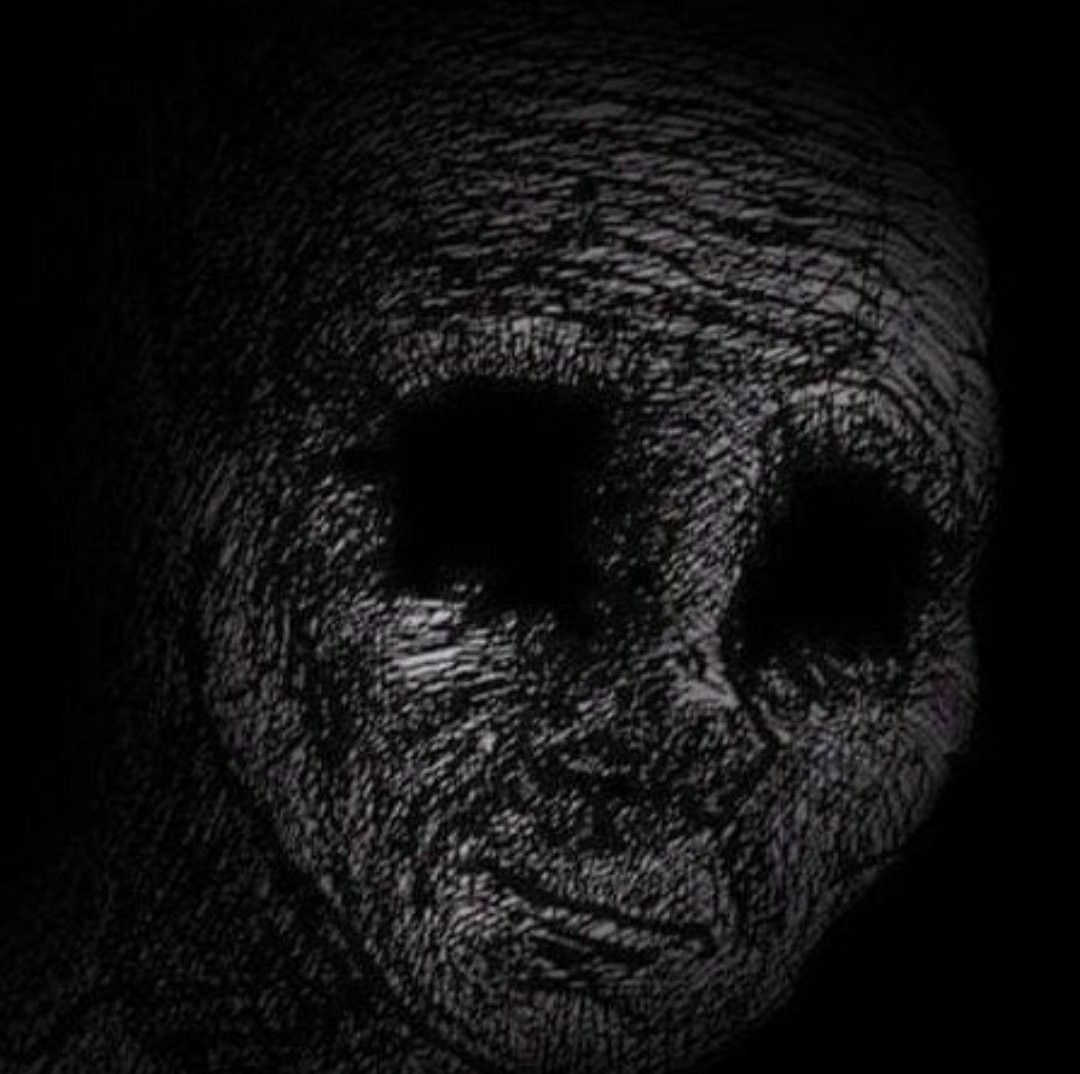